In [1]:
import tensorflow as tf 
from tensorflow import keras


In [3]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(train_images, train_labels),(test_images, test_labels)=fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 99s 4us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 15s 3us/step


In [4]:
print(f"Training images: {train_images.shape}")
print(f"Test images: {test_images.shape}")

Training images: (60000, 28, 28)
Test images: (10000, 28, 28)


In [5]:
# Preprocess
train_images = train_images / 255.0
test_images = test_images / 255.0

In [9]:
# Build a simple model
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')])

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("--- Training Shuru ---")
history = model.fit(train_images, train_labels, epochs=5, validation_split=0.1)
print("--- Training Khatam! ---")


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.8237 - loss: 0.5077 - val_accuracy: 0.8512 - val_loss: 0.4089
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8649 - loss: 0.3777 - val_accuracy: 0.8627 - val_loss: 0.3727
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8777 - loss: 0.3372 - val_accuracy: 0.8718 - val_loss: 0.3579
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8866 - loss: 0.3121 - val_accuracy: 0.8638 - val_loss: 0.3605
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.8917 - loss: 0.2931 - val_accuracy: 0.8817 - val_loss: 0.3399
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.8974 - loss: 0.2801 - val_accuracy: 0.8788 - val_loss: 0.3365
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.9004 - loss: 0.2683 - val_accuracy: 0.8822 - val_loss: 0.3181
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.9052 - 

In [8]:
# Evaluate
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Test accuracy: {test_acc}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.0956 - loss: 2.3026
Test accuracy: 0.09560000151395798


In [11]:
import matplotlib.pyplot as plt
import numpy as np

Test Accuracy: 88.03%

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Model ki Prediction: Shirt
Asal Cheez (True Label): Shirt


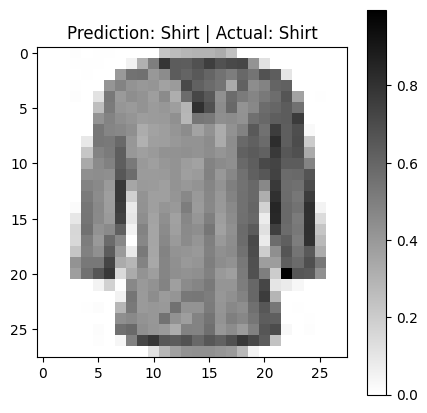

In [18]:

# Fashion MNIST ki 10 categories ke naam
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# 1. Model ki overall Test Accuracy check karna
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
print(f"Test Accuracy: {test_acc*100:.2f}%\n")

# 2. Test images par Predictions lena
predictions = model.predict(test_images)

# 3. Kisi ek image ko check karna (Aap 0 ki jagah 1, 2, 3... likh kar dusri images dekh sakte hain)
img_index = 4
 
predicted_label = np.argmax(predictions[img_index]) # Sab se bari probability wala index
true_label = test_labels[img_index]

print(f"Model ki Prediction: {class_names[predicted_label]}")
print(f"Asal Cheez (True Label): {class_names[true_label]}")

# 4. Image ko Graph/Plot mein dikhana
plt.figure(figsize=(5, 5))
plt.imshow(test_images[img_index], cmap=plt.cm.binary)
plt.title(f"Prediction: {class_names[predicted_label]} | Actual: {class_names[true_label]}")
plt.colorbar()
plt.show()